# Esperimenti V1 e V2 - proprietà passive e forma dello spike

Due esperimenti di **validazione** del neurone MNTB sano (`mntb_hh_kv3_neuron.nestml`, parametri di Macica 2003).

| Esperimento | Domanda | Stimolo | Cosa misuro |
|---|---|---|---|
| **V1** | Quanto è "facile" cambiare la tensione del neurone? | piccoli gradini di corrente **negativi** (100 ms) | resistenza di ingresso **Rin** e costante di tempo **τ** |
| **V2** | Com'è fatto un singolo spike? | **un** impulso da 1.4 nA per 0.25 ms | half-width, picco, ampiezza, dV/dt massima e minima |

In V2 lo spike viene simulato con 3 valori di `g_Kv3` (150 nS controllo, 100 nS come con PMA, 0 nS senza Kv3)
per vedere quanto Kv3 decide la forma dello spike.

**Nota sul ritardo:** in questo notebook il generatore di corrente è collegato al neurone con ritardo `dt` (0.01 ms)
invece del ritardo di default di NEST (1 ms), e i tempi sono misurati da quando la corrente arriva davvero al neurone.


In [1]:
# ============================================================
# 0. SETUP: import, compilazione del modello, funzione di simulazione
# ============================================================

import os
os.environ["PYNEST_QUIET"] = "1"    # nasconde il banner di NEST

import numpy as np
import matplotlib.pyplot as plt
import nest
nest.set_verbosity("M_WARNING")    # mostra solo avvisi ed errori di NEST, non i messaggi informativi
import pynestml
from pynestml.codegeneration.nest_code_generator_utils import NESTCodeGeneratorUtils

print("NEST  :", nest.__version__)
print("NESTML:", pynestml.__version__)

# Genera il codice C++, lo compila e lo carica in NEST (circa 1 minuto)
# Passo il NOME del file e non il suo contenuto: se riceve il testo del modello, NESTML
# riscrive mntb_hh_kv3_neuron.nestml nella cartella corrente aggiungendo ogni volta
# una riga vuota in fondo (pynestml nest_code_generator_utils.py, righe 101-104).
wt_module, wt_model = NESTCodeGeneratorUtils.generate_code_for("mntb_hh_kv3_neuron.nestml")
print("Modello:", wt_model)

dt = 0.01   # ms - passo di simulazione


def run_simulation(amplitude_times, amplitude_values, sim_time, params=None):
    # Simula il neurone con una corrente a gradini e restituisce tempi (ms) e V_m (mV).
    #   amplitude_times  : istanti (ms) in cui la corrente cambia valore
    #   amplitude_values : valore della corrente (pA) a partire da ciascun istante
    #   sim_time         : durata totale della simulazione (ms)
    #   params           : parametri del neurone da cambiare, es. {"g_Kv3": 100.0}
    nest.ResetKernel()
    nest.SetKernelStatus({"resolution": dt})
    nest.Install(wt_module)

    neuron = nest.Create(wt_model, 1, params=params or {})

    stimulus = nest.Create(
        "step_current_generator",
        params={"amplitude_times": amplitude_times,
                "amplitude_values": amplitude_values},
    )
    multimeter = nest.Create("multimeter", params={"record_from": ["V_m"], "interval": dt})

    # ritardo minimo (dt) invece del default di 1 ms
    nest.Connect(stimulus, neuron, syn_spec={"delay": dt})
    nest.Connect(multimeter, neuron)

    nest.Simulate(sim_time)

    events = multimeter.get("events")
    order = np.argsort(events["times"])
    return events["times"][order], events["V_m"][order]


NEST  : 3.9.0
NESTML: 8.2.0


[ODE-toolbox] WARNING:Not preserving expression for variable "refr_t" as it is solved by propagator solver


Modello: mntb_hh_kv3_neuron_nestml


## V1 - Resistenza di ingresso (Rin) e costante di tempo (τ)

**Idea:** inietto una piccola corrente **negativa** e costante. La tensione scende un po' e si assesta su un nuovo valore.
- **Rin = ΔV / I**: quanto si sposta la tensione per ogni pA iniettato. Rin alta = neurone "facile da spostare".
- **τ**: quanto tempo serve per arrivare al 63% dello spostamento finale. Dice quanto è "lenta" la membrana.

Uso correnti negative e piccole perché così i canali voltaggio-dipendenti cambiano poco e misuro soprattutto le proprietà "passive".

**Protocollo:** 100 ms di attesa (il neurone si assesta al riposo), poi un gradino di 100 ms di −10, −20, −30, −50 pA.

**Valori di riferimento:** Rin ≈ 79 MΩ (Wang/Choudhury), WT 98.7 MΩ e τ 3.90 ms (Markkula, topi di 1 mese).


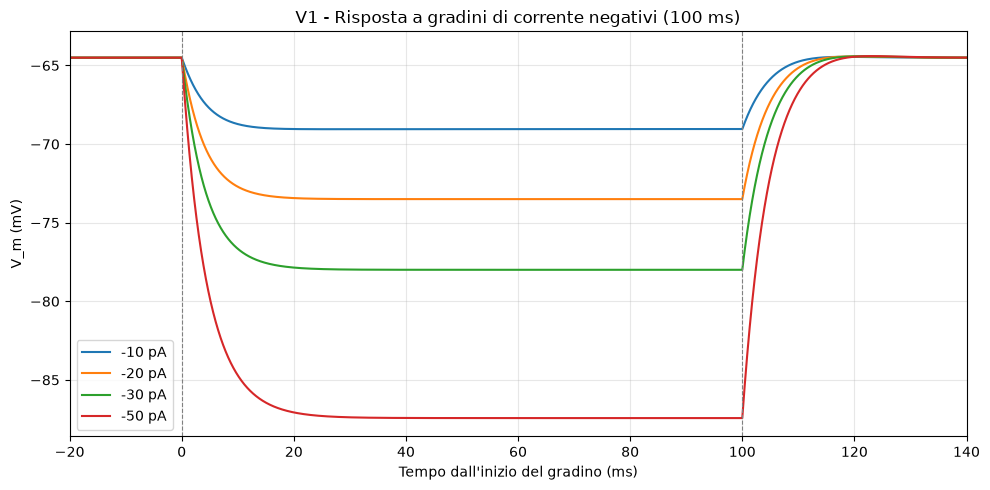

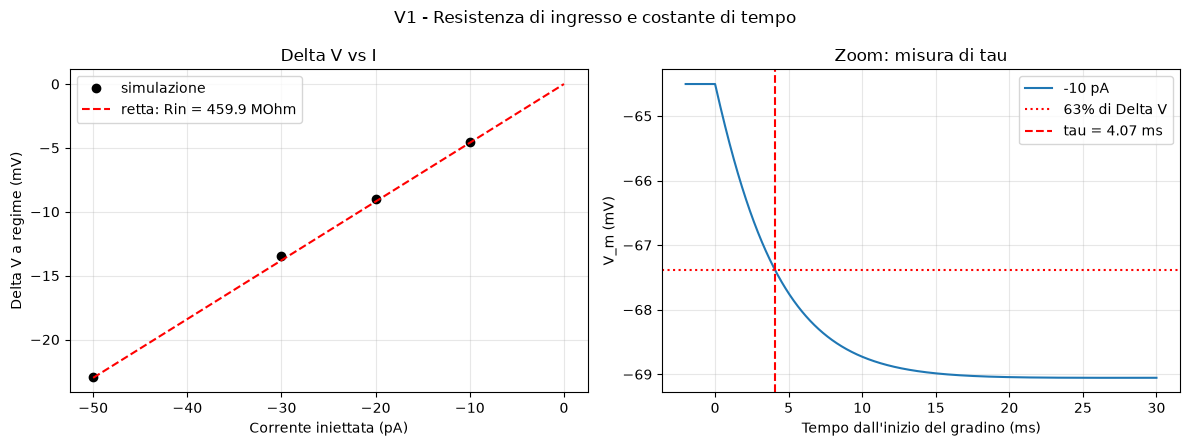

V1 - RIEPILOGO
  I (pA)  V_rest (mV)  V_ss (mV)   dV (mV)  Rin (MOhm)  tau (ms)
     -10       -64.51     -69.05     -4.55       454.7      4.07
     -20       -64.51     -73.50     -9.00       449.8      4.15
     -30       -64.51     -78.00    -13.49       449.7      4.27
     -50       -64.51     -87.43    -22.92       458.4      4.55
--------------------------------------------------------------
Rin dalla retta Delta V vs I: 459.9 MOhm
Riferimenti: Rin ~79 MOhm (Wang/Choudhury), 98.7 MOhm e tau 3.90 ms (Markkula WT)


In [2]:
# ============================================================
# V1 - Rin e tau con gradini di corrente negativi
# ============================================================

t_settle = 100.0                         # ms - attesa iniziale per arrivare al riposo
step_dur = 100.0                         # ms - durata del gradino
step_amps = [-10.0, -20.0, -30.0, -50.0] # pA
sim_time = t_settle + step_dur + 50.0

results_V1 = []

for amp in step_amps:
    t, V = run_simulation([t_settle, t_settle + step_dur], [amp, 0.0], sim_time)

    t_on = t_settle + dt                 # istante in cui la corrente arriva al neurone
    t_off = t_on + step_dur

    # Potenziale prima del gradino (media degli ultimi 10 ms)
    V_rest = np.mean(V[(t >= t_on - 10.0) & (t < t_on)])
    # Potenziale a regime durante il gradino (media degli ultimi 10 ms del gradino)
    V_ss = np.mean(V[(t >= t_off - 10.0) & (t < t_off)])

    dV = V_ss - V_rest                   # mV
    Rin = dV / amp * 1000.0              # mV/pA = GOhm -> x1000 = MOhm

    # tau: primo istante in cui V raggiunge il 63.2% dello spostamento finale
    target = V_rest + 0.632 * dV
    during = (t >= t_on) & (t < t_off)
    reached = np.where(V[during] <= target)[0]
    tau = t[during][reached[0]] - t_on if len(reached) > 0 else np.nan

    results_V1.append({"amp": amp, "t": t, "V": V, "t_on": t_on, "V_rest": V_rest,
                       "V_ss": V_ss, "dV": dV, "Rin": Rin, "tau": tau})

# Rin complessiva: pendenza della retta Delta V vs I
amps = np.array([r["amp"] for r in results_V1])
dVs = np.array([r["dV"] for r in results_V1])
slope = np.polyfit(amps, dVs, 1)[0]      # mV/pA
Rin_fit = slope * 1000.0                 # MOhm

# ------------------------------------------------------------
# Figura 1 - Tracce di tensione
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
for r in results_V1:
    ax.plot(r["t"] - r["t_on"], r["V"], label=f'{r["amp"]:.0f} pA')
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(step_dur, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlim(-20, step_dur + 40)
ax.set_xlabel("Tempo dall'inizio del gradino (ms)")
ax.set_ylabel("V_m (mV)")
ax.set_title("V1 - Risposta a gradini di corrente negativi (100 ms)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figura 2 - Delta V in funzione della corrente (retta -> Rin)
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.plot(amps, dVs, "ko", label="simulazione")
x_fit = np.linspace(amps.min(), 0, 50)
ax.plot(x_fit, slope * x_fit, "r--", label=f"retta: Rin = {Rin_fit:.1f} MOhm")
ax.set_xlabel("Corrente iniettata (pA)")
ax.set_ylabel("Delta V a regime (mV)")
ax.set_title("Delta V vs I")
ax.grid(alpha=0.3)
ax.legend()

# Zoom sulla carica per il gradino piu' piccolo, con tau segnata
ax = axes[1]
r = results_V1[0]
mask = (r["t"] >= r["t_on"] - 2) & (r["t"] <= r["t_on"] + 30)
ax.plot(r["t"][mask] - r["t_on"], r["V"][mask], label=f'{r["amp"]:.0f} pA')
ax.axhline(r["V_rest"] + 0.632 * r["dV"], color="red", linestyle=":", label="63% di Delta V")
if not np.isnan(r["tau"]):
    ax.axvline(r["tau"], color="red", linestyle="--", label=f'tau = {r["tau"]:.2f} ms')
ax.set_xlabel("Tempo dall'inizio del gradino (ms)")
ax.set_ylabel("V_m (mV)")
ax.set_title("Zoom: misura di tau")
ax.grid(alpha=0.3)
ax.legend()

fig.suptitle("V1 - Resistenza di ingresso e costante di tempo")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Riepilogo numerico
# ------------------------------------------------------------
print("==============================================================")
print("V1 - RIEPILOGO")
print("==============================================================")
print(f"{'I (pA)':>8} {'V_rest (mV)':>12} {'V_ss (mV)':>10} {'dV (mV)':>9} {'Rin (MOhm)':>11} {'tau (ms)':>9}")
for r in results_V1:
    print(f'{r["amp"]:>8.0f} {r["V_rest"]:>12.2f} {r["V_ss"]:>10.2f} {r["dV"]:>9.2f} {r["Rin"]:>11.1f} {r["tau"]:>9.2f}')
print("--------------------------------------------------------------")
print(f"Rin dalla retta Delta V vs I: {Rin_fit:.1f} MOhm")
print("Riferimenti: Rin ~79 MOhm (Wang/Choudhury), 98.7 MOhm e tau 3.90 ms (Markkula WT)")


## V2 - Forma del singolo spike

**Idea:** do **un solo** impulso (1.4 nA, 0.25 ms, come nei treni di A1/A2) e misuro com'è fatto lo spike:
- **picco** e **ampiezza** (picco − riposo);
- **half-width**: larghezza dello spike a metà ampiezza, cioè quanto dura;
- **dV/dt massima** (velocità di salita, dipende soprattutto dal sodio) e **minima** (velocità di discesa, dipende soprattutto da Kv3);
- **latenza**: tempo da quando la corrente arriva a quando lo spike raggiunge il picco.

Ripeto con `g_Kv3` = 150 nS (controllo), 100 nS (come con PMA) e 0 nS (senza Kv3, come con TEA o knockout).

**Valori di riferimento (MNTB):** half-width 0.31 ± 0.08 ms (Choudhury WT) / 0.221 ms (Markkula WT);
picco ≈ +29 mV (Macica) / +21.7 mV (Markkula); dV/dt max ≈ 567 mV/ms e min ≈ −447 mV/ms (Markkula WT);
pendenza media di salita 172 mV/ms (Macica).


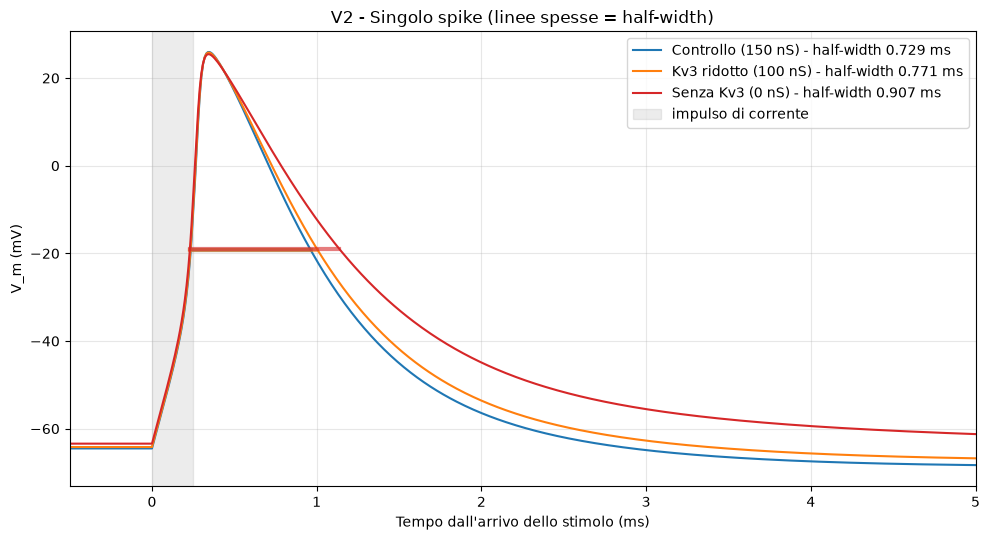

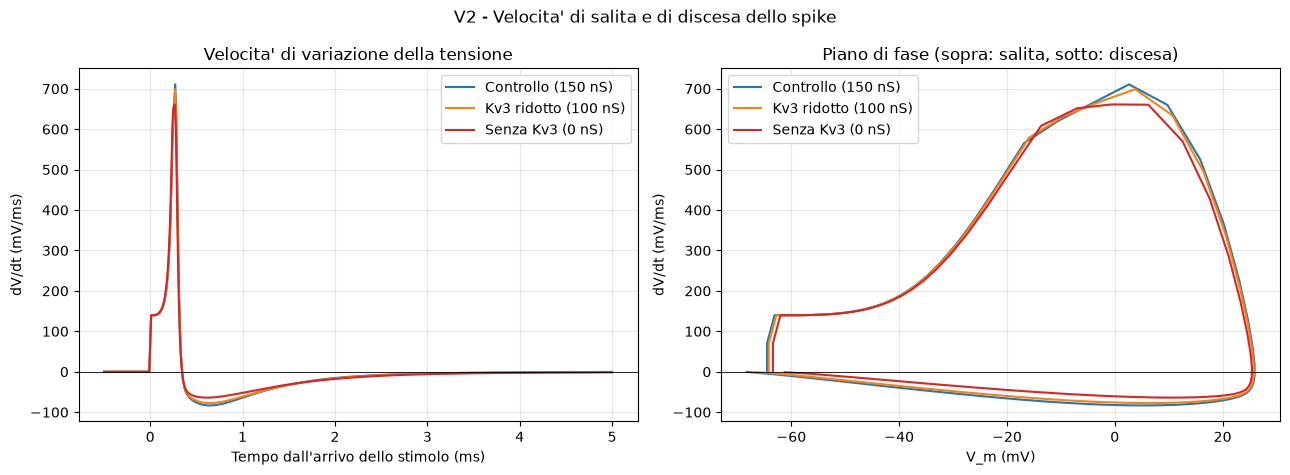

V2 - RIEPILOGO
   g_Kv3  Spike?   V_rest    Picco  Ampiezza  Latenza  Half-width  dV/dt max  dV/dt min
    (nS)             (mV)     (mV)      (mV)     (ms)        (ms)    (mV/ms)    (mV/ms)
     150      si   -64.51    25.94     90.45    0.350       0.729      710.7      -83.3
     100      si   -64.19    25.81     89.99    0.340       0.771      699.0      -77.4
       0      si   -63.41    25.45     88.86    0.340       0.907      661.2      -64.0
-----------------------------------------------------------------------------------------------------
Riferimenti WT: half-width 0.31 +/- 0.08 ms (Choudhury) / 0.221 ms (Markkula); picco ~ +29 mV (Macica);
                dV/dt max ~ 567 mV/ms, dV/dt min ~ -447 mV/ms (Markkula)


In [3]:
# ============================================================
# V2 - Forma del singolo spike con diversi valori di g_Kv3
# ============================================================

t_stim = 100.0          # ms - istante dell'impulso (dopo l'assestamento al riposo)
pulse_amp = 1400.0      # pA = 1.4 nA
pulse_width = 0.25      # ms
sim_time = t_stim + 30.0
g_kv3_values = [150.0, 100.0, 0.0]   # nS
labels = {150.0: "Controllo (150 nS)", 100.0: "Kv3 ridotto (100 nS)", 0.0: "Senza Kv3 (0 nS)"}

results_V2 = []

for g in g_kv3_values:
    t, V = run_simulation([t_stim, t_stim + pulse_width], [pulse_amp, 0.0], sim_time,
                          params={"g_Kv3": g})

    t_on = t_stim + dt                       # arrivo reale della corrente
    rel_t = t - t_on
    dVdt = np.gradient(V, t)                 # mV/ms

    V_rest = np.mean(V[(rel_t >= -5.0) & (rel_t < 0)])

    # Cerco il picco nei 5 ms dopo lo stimolo
    win = (rel_t >= 0) & (rel_t <= 5.0)
    i_peak = np.where(win)[0][np.argmax(V[win])]
    V_peak = V[i_peak]
    latency = rel_t[i_peak]
    amplitude = V_peak - V_rest

    # Half-width: tempi in cui V attraversa la meta' dell'ampiezza (interpolazione lineare)
    half = V_rest + amplitude / 2.0
    i_start = np.where(win)[0][0]
    rise_idx = np.where(V[i_start:i_peak + 1] >= half)[0]
    fall_idx = np.where(V[i_peak:] <= half)[0]
    if len(rise_idx) > 0 and len(fall_idx) > 0:
        i1 = i_start + rise_idx[0]
        i2 = i_peak + fall_idx[0]
        t_rise = np.interp(half, [V[i1 - 1], V[i1]], [rel_t[i1 - 1], rel_t[i1]])
        t_fall = np.interp(half, [V[i2], V[i2 - 1]], [rel_t[i2], rel_t[i2 - 1]])
        half_width = t_fall - t_rise
    else:
        t_rise = t_fall = half_width = np.nan

    # dV/dt massima (salita) e minima (discesa) nei 5 ms dopo lo stimolo
    dVdt_max = np.max(dVdt[win])
    dVdt_min = np.min(dVdt[win])

    is_spike = V_peak > 0.0
    results_V2.append({"g": g, "rel_t": rel_t, "V": V, "dVdt": dVdt, "V_rest": V_rest,
                       "V_peak": V_peak, "amplitude": amplitude, "latency": latency,
                       "half": half, "t_rise": t_rise, "t_fall": t_fall,
                       "half_width": half_width, "dVdt_max": dVdt_max,
                       "dVdt_min": dVdt_min, "is_spike": is_spike})

colors = {150.0: "tab:blue", 100.0: "tab:orange", 0.0: "tab:red"}

# ------------------------------------------------------------
# Figura 1 - Spike sovrapposti con la half-width segnata
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5.5))
for r in results_V2:
    c = colors[r["g"]]
    ax.plot(r["rel_t"], r["V"], color=c, label=f'{labels[r["g"]]} - half-width {r["half_width"]:.3f} ms')
    if not np.isnan(r["half_width"]):
        ax.plot([r["t_rise"], r["t_fall"]], [r["half"], r["half"]], color=c, linewidth=3, alpha=0.6)
ax.axvspan(0, pulse_width, color="gray", alpha=0.15, label="impulso di corrente")
ax.set_xlim(-0.5, 5.0)
ax.set_xlabel("Tempo dall'arrivo dello stimolo (ms)")
ax.set_ylabel("V_m (mV)")
ax.set_title("V2 - Singolo spike (linee spesse = half-width)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figura 2 - dV/dt nel tempo e piano di fase (dV/dt vs V)
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for r in results_V2:
    c = colors[r["g"]]
    m = (r["rel_t"] >= -0.5) & (r["rel_t"] <= 5.0)
    axes[0].plot(r["rel_t"][m], r["dVdt"][m], color=c, label=labels[r["g"]])
    axes[1].plot(r["V"][m], r["dVdt"][m], color=c, label=labels[r["g"]])

axes[0].axhline(0, color="black", linewidth=0.6)
axes[0].set_xlabel("Tempo dall'arrivo dello stimolo (ms)")
axes[0].set_ylabel("dV/dt (mV/ms)")
axes[0].set_title("Velocita' di variazione della tensione")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].axhline(0, color="black", linewidth=0.6)
axes[1].set_xlabel("V_m (mV)")
axes[1].set_ylabel("dV/dt (mV/ms)")
axes[1].set_title("Piano di fase (sopra: salita, sotto: discesa)")
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.suptitle("V2 - Velocita' di salita e di discesa dello spike")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Riepilogo numerico
# ------------------------------------------------------------
print("=====================================================================================================")
print("V2 - RIEPILOGO")
print("=====================================================================================================")
print(f"{'g_Kv3':>8} {'Spike?':>7} {'V_rest':>8} {'Picco':>8} {'Ampiezza':>9} {'Latenza':>8} "
      f"{'Half-width':>11} {'dV/dt max':>10} {'dV/dt min':>10}")
print(f"{'(nS)':>8} {'':>7} {'(mV)':>8} {'(mV)':>8} {'(mV)':>9} {'(ms)':>8} "
      f"{'(ms)':>11} {'(mV/ms)':>10} {'(mV/ms)':>10}")
for r in results_V2:
    print(f'{r["g"]:>8.0f} {("si" if r["is_spike"] else "no"):>7} {r["V_rest"]:>8.2f} {r["V_peak"]:>8.2f} '
          f'{r["amplitude"]:>9.2f} {r["latency"]:>8.3f} {r["half_width"]:>11.3f} '
          f'{r["dVdt_max"]:>10.1f} {r["dVdt_min"]:>10.1f}')
print("-----------------------------------------------------------------------------------------------------")
print("Riferimenti WT: half-width 0.31 +/- 0.08 ms (Choudhury) / 0.221 ms (Markkula); picco ~ +29 mV (Macica);")
print("                dV/dt max ~ 567 mV/ms, dV/dt min ~ -447 mV/ms (Markkula)")


## Come leggere i risultati

- **V1:** se Rin è molto più alta dei valori sperimentali (≈ 80–100 MΩ), il modello ha "poche perdite" a riposo
  (poca conduttanza aperta). Se τ è molto diversa da ≈ 3–4 ms, il rapporto tra capacità e conduttanze a riposo è diverso da quello reale.
  Nota: τ ≈ Rin · C, e qui C = 10 pF (Macica), mentre Markkula misura ≈ 42 pF in topi più grandi.
- **V2:** il confronto chiave è la **half-width** del controllo con ≈ 0.2–0.3 ms. Se è molto più larga, lo spike dura troppo
  e il neurone non riesce a seguire treni ad alta frequenza (come visto in A1/A2).
  Il confronto tra 150, 100 e 0 nS mostra **quanto Kv3 accorcia lo spike**: la dV/dt minima (discesa) dovrebbe
  peggiorare togliendo Kv3, mentre la dV/dt massima (salita, dovuta al sodio) dovrebbe cambiare poco.
